# Machine Learning in Cyber - MSC2621CYS - CB018199
### Question 2
### Just run it. Script will automatically download the dataset from Hugging face
*How to run**
- Open this notebook in **Google Colab**.
- Runtime → Change runtime type → **GPU** (optional, speeds up the CNN) and, ideally,
  a **High-RAM** runtime — the combined dataset is ~2.8 million rows.
- Run cells top to bottom (`Runtime → Run all`). No manual upload is needed — all
  8 CSVs are pulled automatically from a public Hugging Face mirror.



In [ ]:
# Install/upgrade the libraries we need
!pip install -q scikit-learn tensorflow matplotlib seaborn pandas


In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, precision_recall_curve, auc
)

import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, Dropout, BatchNormalization
from keras.utils import to_categorical
from keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_style("whitegrid")


In [ ]:
#  Load all 8 official CIC-IDS2017 CSV files
BASE_URL = "https://huggingface.co/datasets/c01dsnap/CIC-IDS2017/resolve/main/"
CSV_FILES = [
    "Monday-WorkingHours.pcap_ISCX.csv",
    "Tuesday-WorkingHours.pcap_ISCX.csv",
    "Wednesday-workingHours.pcap_ISCX.csv",
    "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv",
    "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
    "Friday-WorkingHours-Morning.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
    "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv",
]

dfs = []
for fname in CSV_FILES:
    print(f"Loading {fname} ...")
    d = pd.read_csv(BASE_URL + fname, low_memory=False)
    d.columns = [c.strip() for c in d.columns]  # strip whitespace from column names
    dfs.append(d)

df = pd.concat(dfs, ignore_index=True)
print(f"\nCombined shape: {df.shape}")
df.head()


Loading Monday-WorkingHours.pcap_ISCX.csv ...
Loading Tuesday-WorkingHours.pcap_ISCX.csv ...
Loading Wednesday-workingHours.pcap_ISCX.csv ...
Loading Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ...
Loading Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ...
Loading Friday-WorkingHours-Morning.pcap_ISCX.csv ...
Loading Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv ...
Loading Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv ...

Combined shape: (2830743, 79)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,49188,4,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,49188,1,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,49486,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [ ]:
# Clean known data quality issues: infinite values and missing values
df = df.replace([np.inf, -np.inf], np.nan)
before = len(df)
df = df.dropna().reset_index(drop=True)
print(f"Dropped {before - len(df)} rows containing inf/NaN values "
      f"({(before - len(df)) / before:.2%} of the data).")
print(f"Remaining shape: {df.shape}")


Dropped 2867 rows containing inf/NaN values (0.10% of the data).
Remaining shape: (2827876, 79)


In [ ]:
# Group the 15 raw labels into 8 standard attack categories
# (raw label text has some encoding/spacing quirks in the original files,
#  so we match on keywords rather than exact strings)
def map_category(label: str) -> str:
    l = str(label).lower()
    if "benign" in l:
        return "Benign"
    if "ddos" in l:
        return "DDoS"
    if "dos" in l or "heartbleed" in l:
        return "DoS"
    if "portscan" in l or "port scan" in l:
        return "PortScan"
    if "bot" in l:
        return "Bot"
    if "patator" in l or "brute force" in l:
        return "Brute Force"
    if "web attack" in l:
        return "Web Attack"
    if "infiltration" in l:
        return "Infiltration"
    return "Other"

df["Category"] = df["Label"].apply(map_category)
print(df["Category"].value_counts())

CLASS_ORDER = df["Category"].value_counts().index.tolist()
n_classes = len(CLASS_ORDER)


Category
Benign          2271320
DoS              251723
PortScan         158804
DDoS             128025
Brute Force       15339
Bot                1956
Web Attack          673
Infiltration         36
Name: count, dtype: int64


/tmp/ipykernel_2519/352539579.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Category", data=df, order=CLASS_ORDER, palette="Set2")


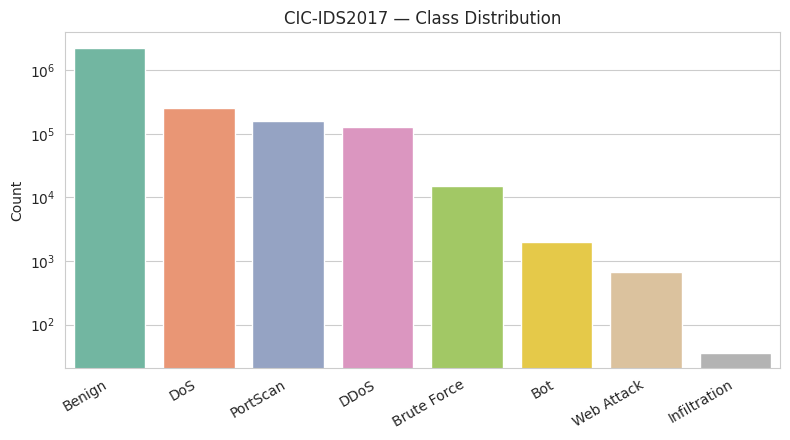

In [ ]:
# Class balance (required visualisation)
plt.figure(figsize=(8, 4.5))
sns.countplot(x="Category", data=df, order=CLASS_ORDER, palette="Set2")
plt.title("CIC-IDS2017 — Class Distribution")
plt.xlabel("")
plt.ylabel("Count")
plt.yscale("log")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [ ]:
# Preprocessing
# Downsample the dominant Benign class for tractable training
MAX_BENIGN_SAMPLES = 100_000  # increase for a more thorough (slower) run

benign_df = df[df["Category"] == "Benign"]
attack_df = df[df["Category"] != "Benign"]

if len(benign_df) > MAX_BENIGN_SAMPLES:
    benign_df = benign_df.sample(n=MAX_BENIGN_SAMPLES, random_state=SEED)

work_df = pd.concat([benign_df, attack_df], ignore_index=True).sample(frac=1, random_state=SEED)
print(f"Working dataset size after downsampling Benign: {len(work_df)}")
print(work_df["Category"].value_counts())


Working dataset size after downsampling Benign: 656556
Category
DoS             251723
PortScan        158804
DDoS            128025
Benign          100000
Brute Force      15339
Bot               1956
Web Attack         673
Infiltration        36
Name: count, dtype: int64


In [ ]:
# Encode categorical features / scale numeric features
drop_cols = ["Label", "Category"]
feature_cols = [c for c in work_df.columns if c not in drop_cols]

categorical_cols = ["Protocol"] if "Protocol" in feature_cols else []
numeric_cols = [c for c in feature_cols if c not in categorical_cols]

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_ORDER)
y_all = label_encoder.transform(work_df["Category"])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    work_df[feature_cols], y_all, test_size=0.2, random_state=SEED, stratify=y_all
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ]
)

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

X_train = np.asarray(X_train.todense()) if hasattr(X_train, "todense") else np.asarray(X_train)
X_test = np.asarray(X_test.todense()) if hasattr(X_test, "todense") else np.asarray(X_test)

y_train_cat = to_categorical(y_train, num_classes=n_classes)
y_test_cat = to_categorical(y_test, num_classes=n_classes)

print("X_train:", X_train.shape, " X_test:", X_test.shape)


X_train: (525244, 78)  X_test: (131312, 78)


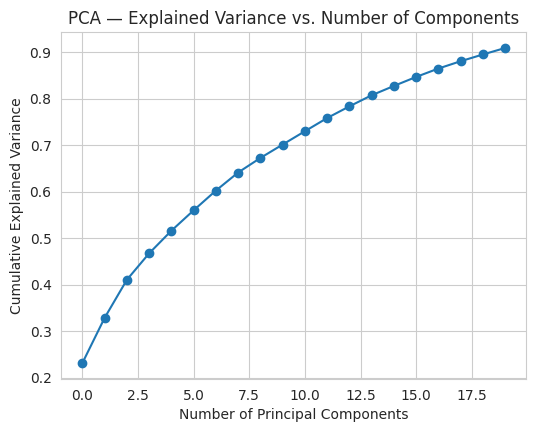

Variance captured by first 10 components: 70.13%


In [ ]:
# PCA - feature-selection / dimensionality-reduction insight
n_pca = min(20, X_train.shape[1])
pca = PCA(n_components=n_pca, random_state=SEED)
pca.fit(X_train)

plt.figure(figsize=(6, 4.5))
plt.plot(np.cumsum(pca.explained_variance_ratio_), marker="o")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Explained Variance vs. Number of Components")
plt.grid(True)
plt.show()

print(f"Variance captured by first 10 components: {np.sum(pca.explained_variance_ratio_[:10]):.2%}")


In [ ]:
# Train a Random Forest for multi-class attack classification
rf = RandomForestClassifier(
    n_estimators=200, max_depth=None, random_state=SEED, n_jobs=-1, class_weight="balanced"
)
rf.fit(X_train, y_train)

rf_preds = rf.predict(X_test)
rf_probs = rf.predict_proba(X_test)

rf_metrics = {
    "Accuracy": accuracy_score(y_test, rf_preds),
    "Precision (macro)": precision_score(y_test, rf_preds, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, rf_preds, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, rf_preds, average="macro", zero_division=0),
}
print("Random Forest performance:")
for k, v in rf_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print(classification_report(y_test, rf_preds, target_names=label_encoder.classes_, zero_division=0))


Random Forest performance:
  Accuracy: 0.9983
  Precision (macro): 0.9270
  Recall (macro): 0.8897
  F1-score (macro): 0.9050

              precision    recall  f1-score   support

      Benign       1.00      1.00      1.00     20000
         Bot       0.97      0.98      0.98       391
 Brute Force       0.97      0.98      0.98      3068
        DDoS       1.00      1.00      1.00     25605
         DoS       1.00      1.00      1.00     50345
Infiltration       1.00      0.86      0.92         7
    PortScan       1.00      1.00      1.00     31761
  Web Attack       0.48      0.30      0.37       135

    accuracy                           1.00    131312
   macro avg       0.93      0.89      0.91    131312
weighted avg       1.00      1.00      1.00    131312



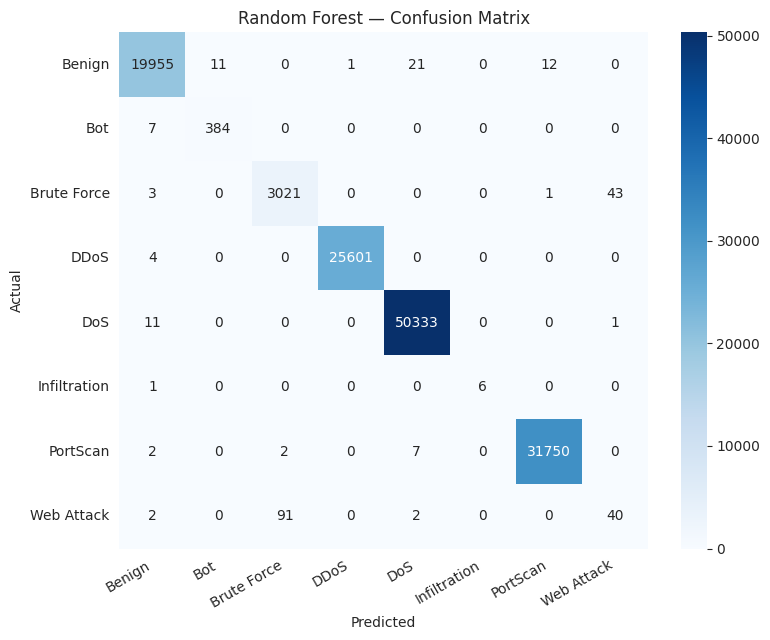

In [ ]:
# Random Forest - Confusion Matrix
cm_rf = confusion_matrix(y_test, rf_preds)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("Random Forest — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


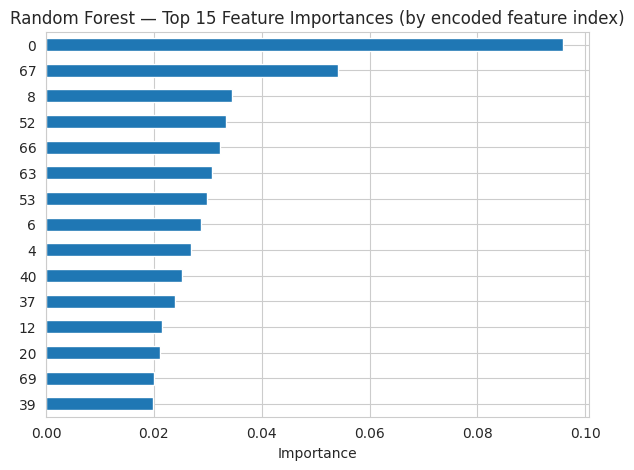

In [ ]:
# Random Forest - Feature importance
importances = pd.Series(rf.feature_importances_).sort_values(ascending=False).head(15)
plt.figure(figsize=(7, 5))
importances.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Random Forest — Top 15 Feature Importances (by encoded feature index)")
plt.xlabel("Importance")
plt.show()


In [ ]:
# Reshape features for Conv1D: (samples, timesteps, channels)
n_features = X_train.shape[1]
X_train_cnn = X_train.reshape((X_train.shape[0], n_features, 1))
X_test_cnn = X_test.reshape((X_test.shape[0], n_features, 1))

print("CNN input shape:", X_train_cnn.shape)


CNN input shape: (525244, 78, 1)


In [ ]:
# Build the 1D-CNN model
cnn_model = Sequential([
    Conv1D(64, kernel_size=3, activation="relu", input_shape=(n_features, 1)),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Conv1D(32, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.4),
    Dense(n_classes, activation="softmax"),
])

cnn_model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
cnn_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 76, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 76, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 38, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 36, 32)         │         6,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 18, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,136 (172.41 KB)

 Trainable params: 44,008 (171.91 KB)

 Non-trainable params: 128 (512.00 B)

In [ ]:
# Train the CNN
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history = cnn_model.fit(
    X_train_cnn, y_train_cat,
    validation_split=0.1,
    epochs=15,
    batch_size=256,
    callbacks=[early_stop],
    verbose=1,
)


Epoch 1/15
1847/1847 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9914 - loss: 0.0322 - val_accuracy: 0.9873 - val_loss: 0.0405
Epoch 2/15
1847/1847 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9915 - loss: 0.0318 - val_accuracy: 0.9879 - val_loss: 0.0403
Epoch 3/15
1847/1847 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9919 - loss: 0.0307 - val_accuracy: 0.9841 - val_loss: 0.0456
Epoch 4/15
1847/1847 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9919 - loss: 0.0299 - val_accuracy: 0.9857 - val_loss: 0.0405
Epoch 5/15
1847/1847 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9908 - loss: 0.0331 - val_accuracy: 0.9858 - val_loss: 0.0476


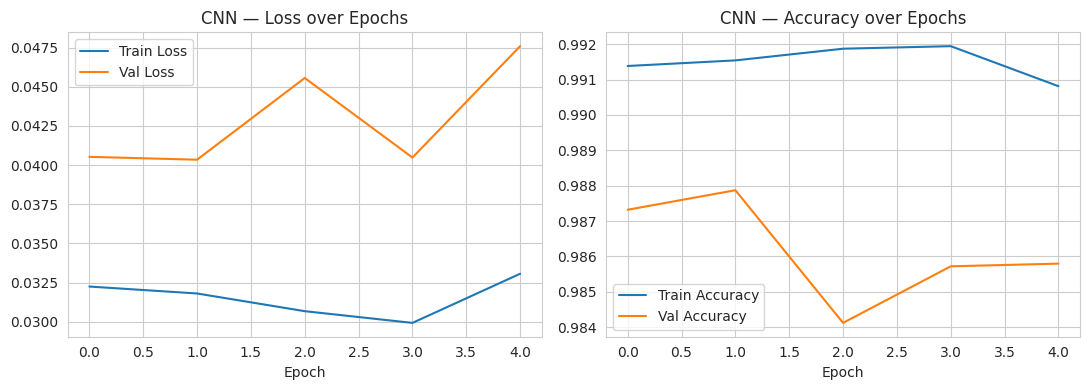

In [ ]:
# Training curves (required visualisation)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("CNN — Loss over Epochs")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("CNN — Accuracy over Epochs")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
# Evaluate the CNN on the held-out test set
cnn_probs = cnn_model.predict(X_test_cnn)
cnn_preds = np.argmax(cnn_probs, axis=1)

cnn_metrics = {
    "Accuracy": accuracy_score(y_test, cnn_preds),
    "Precision (macro)": precision_score(y_test, cnn_preds, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, cnn_preds, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, cnn_preds, average="macro", zero_division=0),
}
print("CNN performance:")
for k, v in cnn_metrics.items():
    print(f"  {k}: {v:.4f}")
print()
print(classification_report(y_test, cnn_preds, target_names=label_encoder.classes_, zero_division=0))


4104/4104 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step
CNN performance:
  Accuracy: 0.9904
  Precision (macro): 0.9704
  Recall (macro): 0.7733
  F1-score (macro): 0.8031

              precision    recall  f1-score   support

      Benign       0.99      0.96      0.97     20000
         Bot       0.86      0.66      0.75       391
 Brute Force       0.93      0.98      0.96      3068
        DDoS       0.99      1.00      1.00     25605
         DoS       0.99      1.00      1.00     50345
Infiltration       1.00      0.57      0.73         7
    PortScan       0.99      1.00      1.00     31761
  Web Attack       1.00      0.01      0.03       135

    accuracy                           0.99    131312
   macro avg       0.97      0.77      0.80    131312
weighted avg       0.99      0.99      0.99    131312



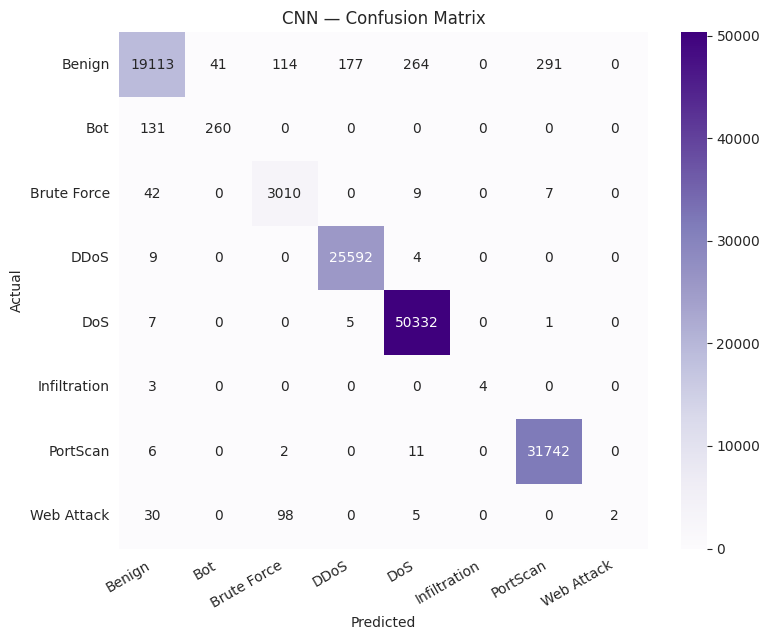

In [ ]:
# CNN - Confusion Matrix
cm_cnn = confusion_matrix(y_test, cnn_preds)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Purples",
            xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.title("CNN — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


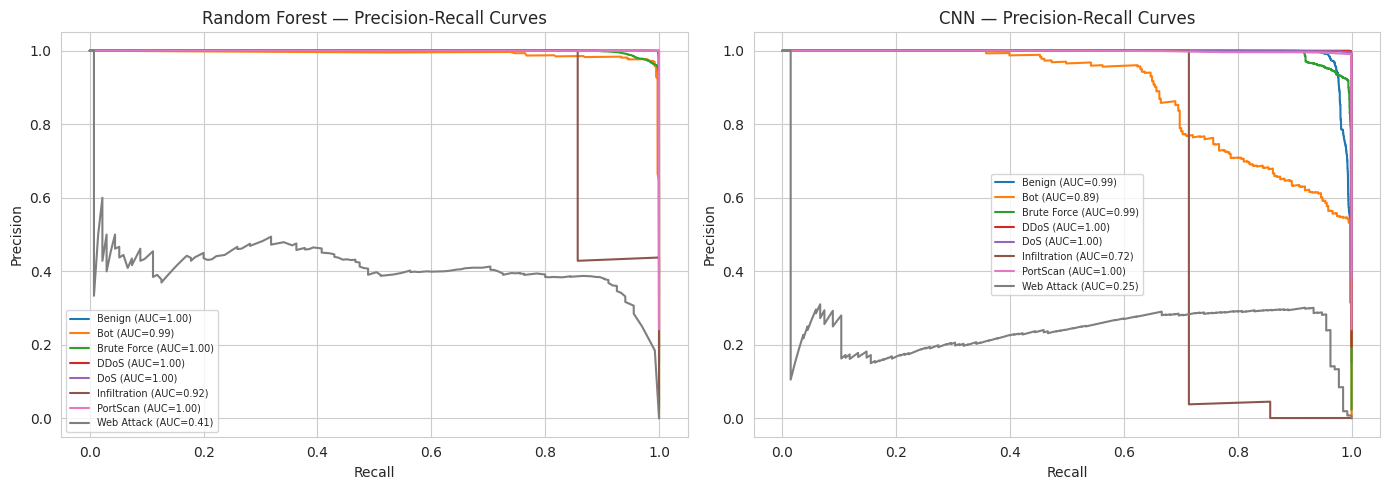

In [ ]:
# Precision-Recall curves (one-vs-rest) for both models
y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i, cls in enumerate(label_encoder.classes_):
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], rf_probs[:, i])
    axes[0].plot(rec, prec, label=f"{cls} (AUC={auc(rec, prec):.2f})")
axes[0].set_title("Random Forest — Precision-Recall Curves")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend(fontsize=7)

for i, cls in enumerate(label_encoder.classes_):
    prec, rec, _ = precision_recall_curve(y_test_bin[:, i], cnn_probs[:, i])
    axes[1].plot(rec, prec, label=f"{cls} (AUC={auc(rec, prec):.2f})")
axes[1].set_title("CNN — Precision-Recall Curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()


               Accuracy  Precision (macro)  Recall (macro)  F1-score (macro)
Random Forest    0.9983             0.9270          0.8897            0.9050
1D-CNN           0.9904             0.9704          0.7733            0.8031


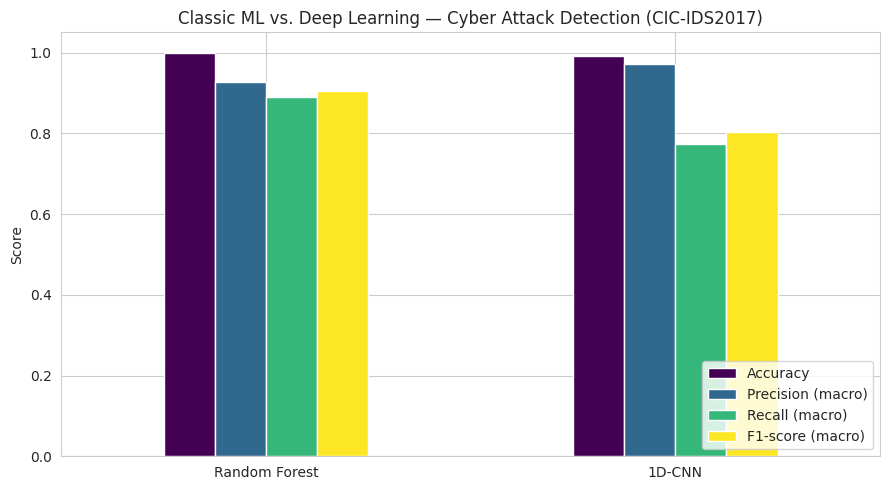

In [ ]:
# Side-by-side comparison table + chart
comparison = pd.DataFrame({
    "Random Forest": rf_metrics,
    "1D-CNN": cnn_metrics,
}).T

print(comparison.round(4))

comparison.plot(kind="bar", figsize=(9, 5), colormap="viridis")
plt.title("Classic ML vs. Deep Learning — Cyber Attack Detection (CIC-IDS2017)")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()
